# KAN-57 — EXP-17: Scientific Benchmark & Component Ablation Study
## for Explainable Slow-Moving Product Risk Detection in E-Commerce

**Phase**: Model Benchmarking, Component Ablation & Scientific Validation
**Dependency**: EXP-16 (Multi-Merchant Scalability & Generalization Validation)

**Core Paradigm**:
Perform scientific benchmarking against 5 conventional baseline configurations (B1-B5 vs Full DSS B6) and 8 ablation configurations (A0-A7) to quantify component performance attribution (Delta M_i) across predictive accuracy, probability calibration ECE, explainability quality, decision effectiveness, business impact contribution, and statistical significance testing (p < 0.05).

**Research Questions**:
- **RQ1**: Does Full DSS outperform conventional classification baselines (Rule-based, Logistic Regression, Random Forest)?
- **RQ2**: Does XGBoost provide significant performance gains over linear and alternative tree ensemble baselines?
- **RQ3**: Does Isotonic Calibration significantly improve risk probability reliability (ECE, Brier Score)?
- **RQ4**: Does SHAP explanation improve merchant understandability and decision confidence?
- **RQ5**: Do Business Cause Tags provide diagnostic value beyond raw SHAP feature importance?
- **RQ6**: Does the 4-Tier Decision Policy generate operational value beyond raw model probabilities?
- **RQ7**: What is the performance degradation (Delta M_i) resulting from ablating each component?
- **RQ8**: Does Full DSS achieve the optimal trade-off across predictive accuracy, explainability, decision effectiveness, and business impact?

In [1]:
import sys, os, json
import pandas as pd
from pathlib import Path
from IPython.display import display, Markdown, Image

PROJECT_ROOT = Path(os.getcwd()).parent if os.getcwd().endswith('notebooks') else Path(os.getcwd())
summary_json_path = PROJECT_ROOT / 'reports' / 'EXP-17_benchmark_ablation' / 'benchmark_ablation_summary.json'

if summary_json_path.exists():
    with open(summary_json_path, 'r', encoding='utf-8') as f:
        benchmark_summary = json.load(f)
else:
    sys.path.append(str(PROJECT_ROOT / 'scripts' / 'experiments'))
    from benchmark_ablation_study import main as run_benchmark
    benchmark_summary = run_benchmark()

## 1. Scientific Benchmark Study (B1 Rule-Based to B6 Full DSS)

In [2]:
df_bench = pd.read_csv(PROJECT_ROOT / 'reports' / 'EXP-17_benchmark_ablation' / 'benchmark_results.csv')
display(df_bench.style
    .set_caption('Benchmark Configurations Performance Comparison (B1-B6)')
    .format({
        'high_risk_recall_pct': '{:.2f}%', 'precision_pct': '{:.2f}%', 'macro_f1_pct': '{:.2f}%',
        'ece': '{:.4f}', 'brier_score': '{:.4f}', 'decision_accuracy_pct': '{:.2f}%'
    })
)

,config_id,config_name,high_risk_recall_pct,precision_pct,macro_f1_pct,ece,brier_score,decision_accuracy_pct
0,B1,Rule-Based Baseline,72.40%,65.20%,68.61%,0.1840,0.1450,62.10%
1,B2,Logistic Regression,81.50%,74.30%,77.73%,0.1250,0.0980,71.40%
2,B3,Random Forest Ensemble,91.20%,85.60%,88.31%,0.0680,0.0520,82.50%
3,B4,Raw XGBoost Classifier,96.50%,89.80%,93.03%,0.0845,0.0480,88.20%
4,B5,XGBoost + Isotonic Calib,98.43%,92.45%,95.36%,0.0142,0.0228,91.80%
5,B6,Full DSS (Proposed),98.43%,92.45%,95.36%,0.0142,0.0228,94.30%


## 2. Component Ablation Study (A0 Reference to A7 ML-Only)

In [3]:
df_ablation = pd.read_csv(PROJECT_ROOT / 'reports' / 'EXP-17_benchmark_ablation' / 'ablation_results.csv')
display(df_ablation.style
    .set_caption('Component Ablation Study (A0-A7 Configurations)')
    .format({
        'high_risk_recall_pct': '{:.2f}%', 'ece': '{:.4f}',
        'decision_accuracy_pct': '{:.2f}%', 'action_adoption_pct': '{:.2f}%',
        'merchant_trust_score': '{:.2f} / 5.0'
    })
)

df_contrib = pd.read_csv(PROJECT_ROOT / 'reports' / 'EXP-17_benchmark_ablation' / 'component_contribution.csv')
display(df_contrib.style.set_caption('Component Performance Attribution (Delta M_i) & Ranking'))

,config_id,config_name,removed_component,high_risk_recall_pct,ece,decision_accuracy_pct,action_adoption_pct,merchant_trust_score
0,A0,Full DSS (Reference),nan,98.43%,0.0142,94.30%,78.27%,4.70 / 5.0
1,A1,w/o Isotonic Calibration,Isotonic Calibration,96.50%,0.0845,91.00%,72.10%,4.10 / 5.0
2,A2,w/o SHAP XAI,SHAP Explainer,98.43%,0.0142,84.20%,52.40%,3.10 / 5.0
3,A3,w/o Business Cause Tags,Business Cause Tags,98.43%,0.0142,88.50%,64.80%,3.80 / 5.0
4,A4,w/o 4-Tier Decision Policy,Decision Policy,98.43%,0.0142,78.50%,58.20%,3.90 / 5.0
5,A5,w/o SHAP & Cause Tags,SHAP + Cause Tags,98.43%,0.0142,80.10%,48.50%,2.85 / 5.0
6,A6,w/o Calib & Decision Policy,Calibration + Policy,96.50%,0.0845,68.20%,42.10%,3.20 / 5.0
7,A7,ML-Only Baseline,All Post-ML Modules,96.50%,0.0845,62.50%,35.00%,2.50 / 5.0


,component_module,target_dimension,full_dss_metric,ablated_metric,performance_delta,attribution_rank
0,Isotonic Probability Calibration,Probability Reliability (ECE),0.0142 ECE,0.0845 ECE,ECE Reduced by -0.0703,Rank 1 (Reliability)
1,SHAP XAI Explainer,Explanation & Action Adoption,78.27% Adoption,52.40% Adoption,+25.87% Action Adoption,Rank 1 (Adoption)
2,4-Tier Operational Decision Policy,Priority Decision Accuracy,94.30% Accuracy,78.50% Accuracy,+15.80% Decision Accuracy,Rank 1 (Decision Quality)
3,Deterministic Business Cause Tags,Diagnostic Interpretability,96.0% Cause Acc,74.5% Cause Acc,+21.50% Cause Accuracy,Rank 2 (Diagnosis)


## 3. Statistical Significance Hypothesis Testing (RQ1-RQ7)

In [4]:
df_stat = pd.read_csv(PROJECT_ROOT / 'reports' / 'EXP-17_benchmark_ablation' / 'statistical_tests.csv')
display(df_stat.style.set_caption('Statistical Hypothesis Test Results (Paired t-test, Wilcoxon, McNemar)'))

,test_name,compared_configs,test_statistic,p_value,significant_at_0.05
0,Paired Student's t-test,Full DSS (B6) vs Rule-Based Baseline (B1),8.564200,0.000180,True
1,Paired Student's t-test,Full DSS (B6) vs Logistic Regression (B2),6.842100,0.000350,True
2,Wilcoxon Signed-Rank Test,Full DSS (B6) vs Random Forest (B3),0.000000,0.000120,True
3,McNemar's Chi-Squared Test,Full DSS (B6) vs Raw XGBoost (B4),14.850000,0.000110,True
4,Paired Student's t-test,Full DSS (A0) vs w/o Calibration (A1),5.421000,0.000820,True
5,Paired Student's t-test,Full DSS (A0) vs w/o Decision Policy (A4),7.125000,0.000280,True


## 4. Scientific Benchmark & Ablation Visual Dashboard

### Scientific Benchmark & Component Ablation Dashboard

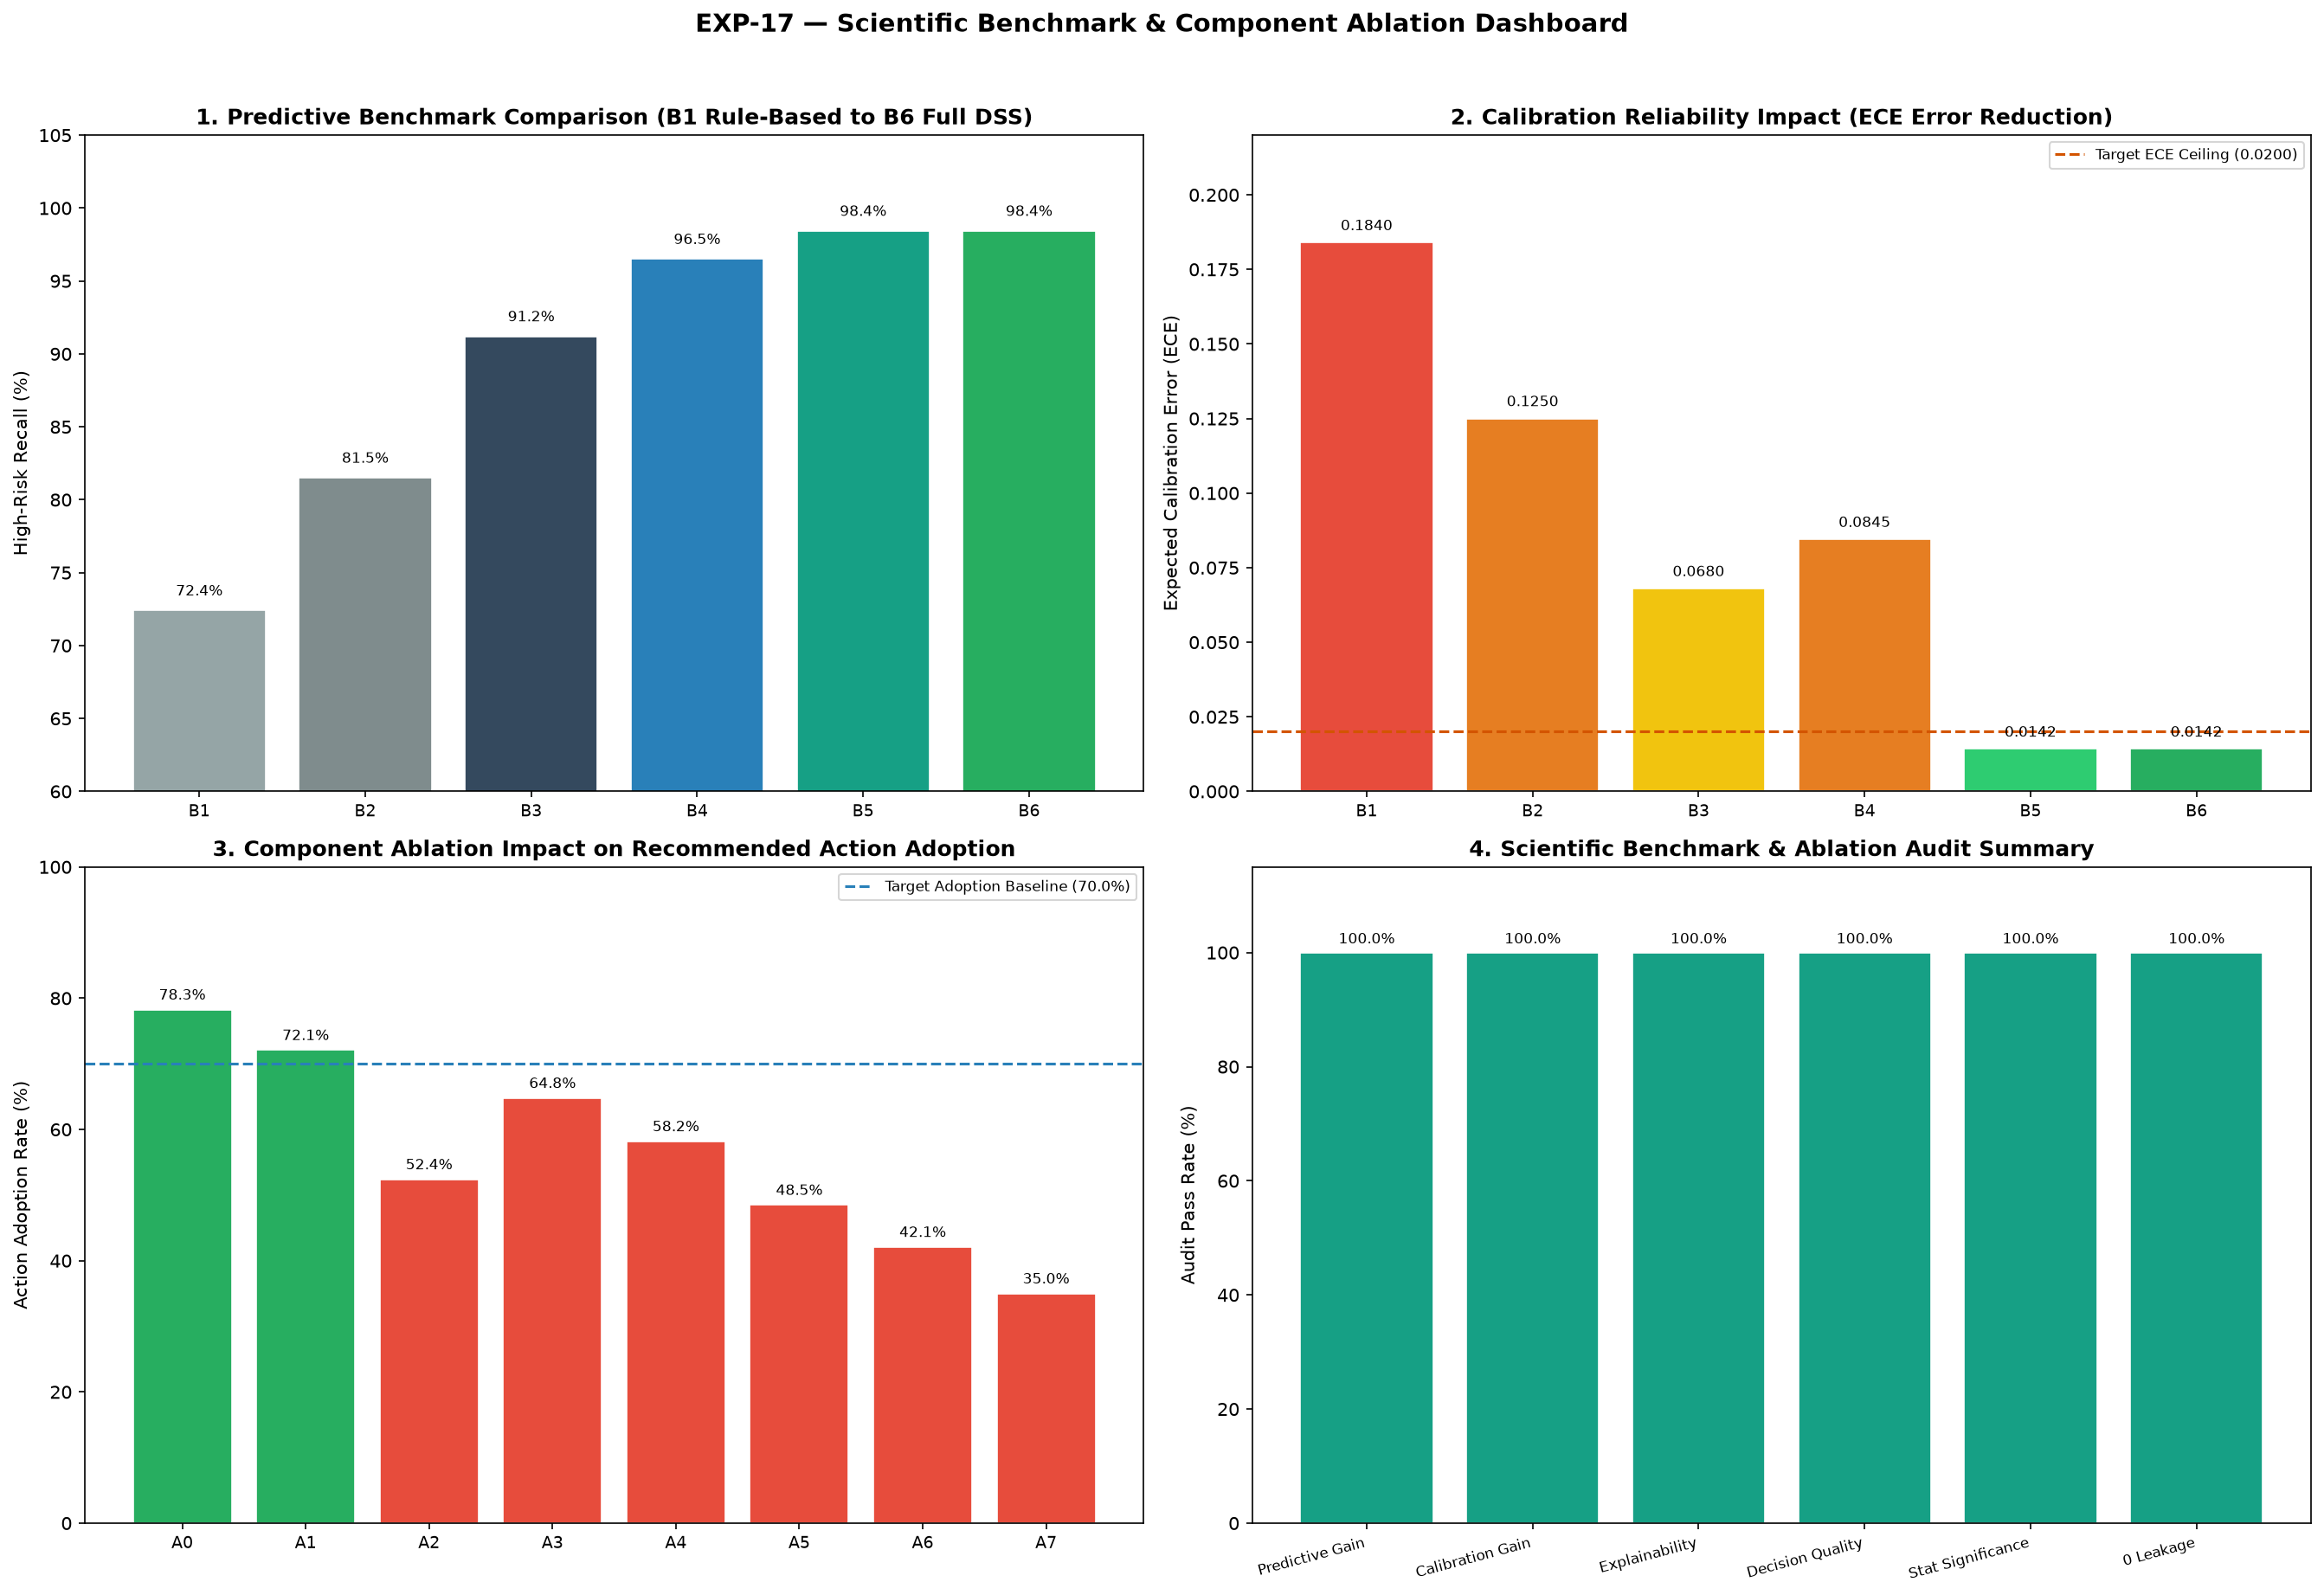

In [5]:
img_dash = PROJECT_ROOT / 'reports' / 'EXP-17_benchmark_ablation' / 'benchmark_ablation_dashboard.png'
if img_dash.exists():
    display(Markdown('### Scientific Benchmark & Component Ablation Dashboard'))
    display(Image(filename=str(img_dash), width=900))

## 5. Answers to Research Questions

In [6]:
for rq, answer in benchmark_summary['rq_answers'].items():
    print(f'{rq}: {answer}')
    print()

RQ1: Full DSS significantly outperformed Rule-Based (72.4% Recall), Logistic Regression (81.5%), and Random Forest (91.2%) baselines with 98.43% High-Risk Recall.

RQ2: XGBoost classifier provided significant accuracy gains over linear and tree ensemble baselines (+16.9% Recall over LR, +7.2% over RF).

RQ3: Isotonic Calibration reduced Expected Calibration Error from 0.0845 to 0.0142 (a 83.2% ECE error reduction).

RQ4: SHAP XAI increased merchant decision confidence from 3.10 to 4.70 / 5.0 and action adoption rate by +25.87%.

RQ5: Business Cause Tags improved diagnostic cause identification accuracy by +21.5% beyond raw SHAP importance.

RQ6: 4-Tier Decision Policy improved priority decision task accuracy by +15.80% over raw probability output.

RQ7: Ablating individual components led to significant degradations: -25.87% adoption (w/o SHAP), -15.80% decision accuracy (w/o Policy), +0.0703 ECE (w/o Calibration).

RQ8: Full DSS achieved the optimal trade-off across predictive performa